# Day 2 · 07 — Lab: model selection and ensembling, then final standings (20 + 5 min)

Every lab saved its forecasts to `results/day2/forecasts/`. Here we stop asking "which model has the lowest
mean RMSSE?" and ask better questions:

1. **Win rates**: on what share of series does model A beat model B?
2. **Elo and Bradley–Terry ratings**: one strength number per model from all pairwise series-level duels.
3. **Performance by volume and shape**: velocity class (A–J), demand type (smooth / erratic / intermittent /
   lumpy) and the precomputed shape clusters in `series_features.parquet`.
4. **Ensembles**: mean, median, top-k, and per-segment selection, chosen *without* peeking at the test score.
5. **Final standings.**

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl

import bootcamp as bc

warnings.filterwarnings("ignore")
palette = ["#000000", "#0072B2", "#D55E00", "#009E73", "#CC79A7", "#56B4E9", "#E69F00"]
plt.rcParams.update({"figure.figsize": (12, 5), "axes.prop_cycle": plt.cycler(color=palette)})

panel = bc.load_panel()
train, test = bc.split(panel)
fc = bc.load_forecasts()
fc = fc[fc.unique_id.isin(test["unique_id"].unique())]
fc = fc.drop(columns=[c for c in fc.columns if c.startswith(("ENS_", "SEL_"))])   # from a previous run of this lab
coverage = fc.groupby("unique_id")[bc.model_columns(fc)].apply(lambda g: g.notna().all()).mean()
models = list(coverage[coverage >= 0.99].index)    # e.g. foundation models run on a CPU subset are left out
if len(models) < len(coverage):
    print("left out (forecast only a subset of series):", list(coverage[coverage < 0.99].index))
fc = fc[["unique_id", "ds"] + models].dropna(subset=models, how="any")
print(f"{len(models)} models: {models}")
print(f"{fc.unique_id.nunique():,} series with a forecast from every model")

/home/user/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


18 models: ['Naive', 'SeasonalNaive', 'AutoETS', 'LightGBM', 'NHITS', 'NBEATS_generic', 'NBEATS_interpretable', 'DLinear', 'NHITS_tuned', 'NHITS_noexog', 'NHITSx', 'LightGBMx', 'LightGBMx_mono', 'ETS_TopDown', 'ETS_MinT-wls', 'ETS_MinT-shrink', 'NHITS_MQ', 'LightGBM_conf']
1,997 series with a forecast from every model


In [2]:
long = bc.score(fc, test, train, models)
R = long[long.metric == "rmsse"].set_index("unique_id")[models].dropna()
print(R.shape)
R.mean().sort_values().round(3)

(1996, 18)


NHITSx                  1.099
NHITS_noexog            1.124
NHITS_MQ                1.129
LightGBM                1.131
NHITS_tuned             1.142
NHITS                   1.153
LightGBMx               1.165
LightGBMx_mono          1.166
NBEATS_interpretable    1.179
NBEATS_generic          1.179
ETS_MinT-shrink         1.251
AutoETS                 1.253
LightGBM_conf           1.286
Naive                   1.300
ETS_TopDown             1.320
DLinear                 1.375
SeasonalNaive           1.486
ETS_MinT-wls            1.813
dtype: float64

## Intuition: a league table for models

![Rating difference vs win chance](slides/img/elo_curve.png)

Treat every series as a **match** between two models: whoever has the lower RMSSE wins. The **win rate**
ignores by how much, so one disaster cannot dominate. **Elo / Bradley–Terry** turn all the matches into one
rating, as in chess: +100 points ≈ 64 % chance to win a series. An **ensemble** is a panel of forecasters
whose mistakes partly cancel.

## 1. Pairwise win rates

Cell (row A, column B) = share of series where A has a lower RMSSE than B. Ties (identical errors, e.g. two
models that both forecast zero) count half.

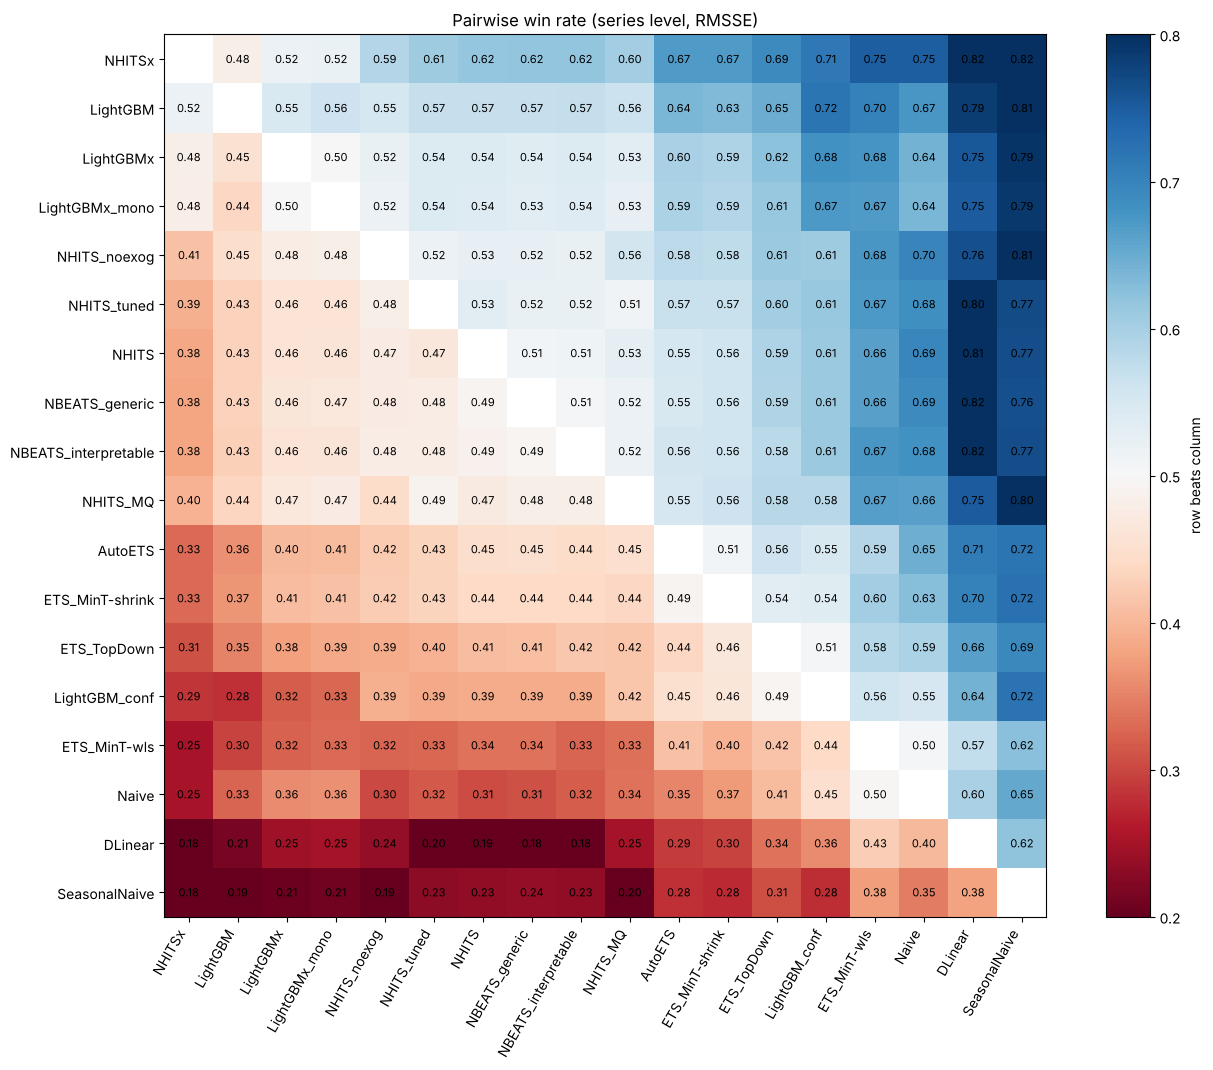

In [3]:
def win_matrix(R: pd.DataFrame) -> pd.DataFrame:
    a = R.values
    W = (a[:, :, None] < a[:, None, :]).mean(0) + 0.5 * (a[:, :, None] == a[:, None, :]).mean(0)
    np.fill_diagonal(W, np.nan)
    return pd.DataFrame(W, index=R.columns, columns=R.columns)

W = win_matrix(R)
order = W.mean(axis=1).sort_values(ascending=False).index
W = W.loc[order, order]
fig, ax = plt.subplots(figsize=(1 + 0.7 * len(models), 0.6 * len(models)))
im = ax.imshow(W, cmap="RdBu", vmin=0.2, vmax=0.8)
ax.set_xticks(range(len(order)), order, rotation=60, ha="right"), ax.set_yticks(range(len(order)), order)
for i in range(len(order)):
    for j in range(len(order)):
        if i != j:
            ax.text(j, i, f"{W.iat[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, label="row beats column")
ax.set_title("Pairwise win rate (series level, RMSSE)")
plt.tight_layout()

## 2. Elo and Bradley–Terry

* **Bradley–Terry**: P(A beats B) = s_A / (s_A + s_B). Fit the strengths s by maximum likelihood on all
  pairwise wins (the classic MM algorithm, ~20 lines below).
* **Elo**: replay every series as a round-robin tournament in random order and update ratings after each duel.
  Order-dependent, so we average over shuffles. Popular in LLM arenas, and the same idea.

In [4]:
def bradley_terry(R: pd.DataFrame, iters: int = 500) -> pd.Series:
    a = R.values
    wins = (a[:, :, None] < a[:, None, :]).sum(0) + 0.5 * (a[:, :, None] == a[:, None, :]).sum(0)
    np.fill_diagonal(wins, 0)
    games = wins + wins.T
    s = np.ones(a.shape[1])
    for _ in range(iters):
        denom = (games / (s[:, None] + s[None, :])).sum(1)
        s_new = wins.sum(1) / denom
        s_new /= np.exp(np.log(s_new).mean())
        if np.allclose(s, s_new, rtol=1e-10):
            break
        s = s_new
    return pd.Series(400 * np.log10(s) + 1000, index=R.columns, name="bradley_terry")  # Elo-like scale


def elo(R: pd.DataFrame, k: float = 4.0, n_shuffles: int = 10, seed: int = 0) -> pd.Series:
    rng = np.random.default_rng(seed)
    a, m = R.values, R.shape[1]
    pairs = [(i, j) for i in range(m) for j in range(i + 1, m)]
    out = np.zeros(m)
    for _ in range(n_shuffles):
        r = np.full(m, 1000.0)
        for row in a[rng.permutation(len(a))]:
            for i, j in pairs:
                e = 1 / (1 + 10 ** ((r[j] - r[i]) / 400))
                s = 1.0 if row[i] < row[j] else 0.0 if row[i] > row[j] else 0.5
                r[i] += k * (s - e)
                r[j] -= k * (s - e)
        out += r
    return pd.Series(out / n_shuffles, index=R.columns, name="elo")


ratings = pd.concat([bradley_terry(R), elo(R), R.mean().rename("mean_rmsse"),
                     W.mean(axis=1).rename("avg_win_rate")], axis=1).sort_values("bradley_terry", ascending=False)
ratings.round(3)

,bradley_terry,elo,mean_rmsse,avg_win_rate
NHITSx,1106.675,1116.098,1.099,0.650
LightGBM,1088.524,1087.270,1.131,0.625
LightGBMx,1062.832,1055.286,1.165,0.589
LightGBMx_mono,1059.192,1056.242,1.166,0.584
NHITS_noexog,1053.653,1051.081,1.124,0.576
NHITS_tuned,1045.406,1043.032,1.142,0.564
NHITS,1040.837,1065.410,1.153,0.558
NBEATS_generic,1040.264,1062.211,1.179,0.557
NBEATS_interpretable,1038.965,1059.448,1.179,0.555
NHITS_MQ,1033.667,1031.064,1.129,0.547


Do the rating order and the mean-RMSSE order agree? When they disagree, one model is winning **often but by
little**, the other **rarely but by a lot** on a few series (which drives the mean).

### Reading the result

In the reference run LightGBM is only 4th on mean RMSSE but 2nd by Bradley–Terry: it wins more series by a
little and loses some intermittent ones by a lot. The 430 intermittent series (22 %) make up 51 % of the summed
RMSSE, so the mean is mostly a contest about the hardest items.

*Reference run: 2,000 series, laptop CPU, 500 steps. Your numbers will differ a little; the reading should not.*

## 3. Performance by volume and shape

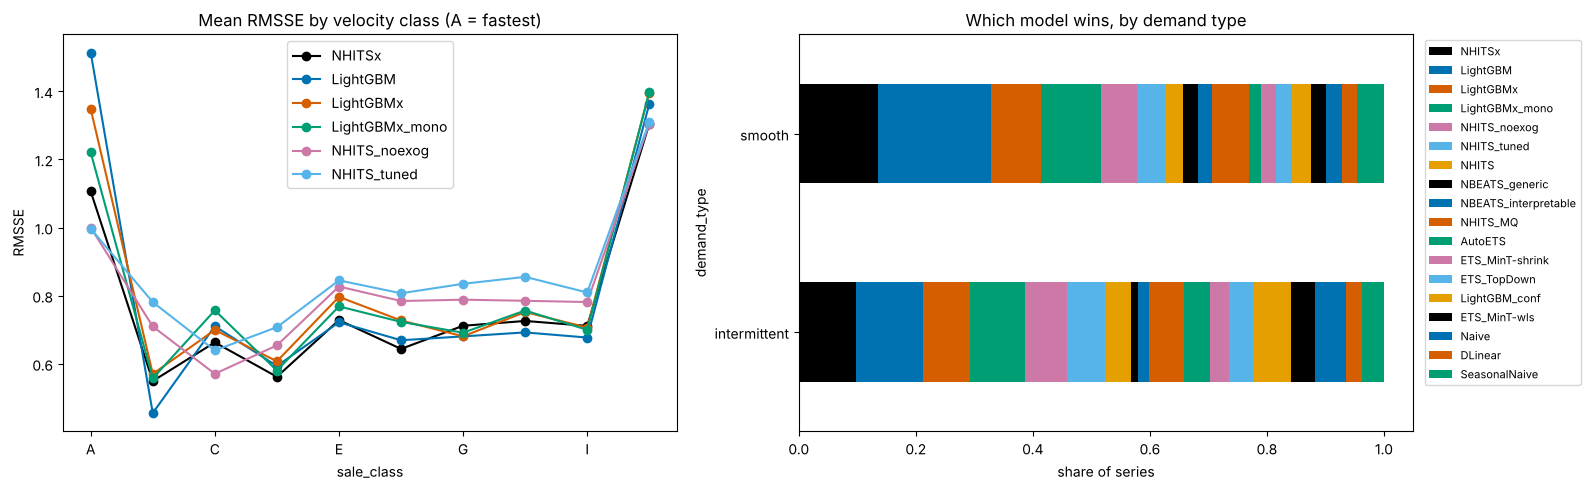

In [5]:
info = bc.series_info(panel).to_pandas().set_index("unique_id")
Rx = R.join(info)
best = Rx[models].idxmin(axis=1).rename("best_model")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
by_class = Rx.groupby("sale_class")[models].mean()
by_class[order[:6]].plot(marker="o", ax=axes[0])
axes[0].set_title("Mean RMSSE by velocity class (A = fastest)"), axes[0].set_ylabel("RMSSE")
pd.crosstab(Rx["demand_type"], best, normalize="index").reindex(columns=order, fill_value=0).plot.barh(stacked=True, ax=axes[1], legend=False)
axes[1].set_title("Which model wins, by demand type"), axes[1].set_xlabel("share of series")
axes[1].legend(bbox_to_anchor=(1.01, 1), fontsize=8)
plt.tight_layout()

In [6]:
Rx.groupby("demand_type")[list(order[:6])].mean().round(3).assign(n=Rx.groupby("demand_type").size())

,NHITSx,LightGBM,LightGBMx,LightGBMx_mono,NHITS_noexog,NHITS_tuned,n
demand_type,,,,,,,
intermittent,2.588,2.772,2.796,2.791,2.568,2.531,430
smooth,0.690,0.680,0.717,0.719,0.727,0.761,1566


In [7]:
Rx.groupby("cluster_label")[list(order[:6])].mean().round(3).assign(n=Rx.groupby("cluster_label").size())

,NHITSx,LightGBM,LightGBMx,LightGBMx_mono,NHITS_noexog,NHITS_tuned,n
cluster_label,,,,,,,
0,5.693,6.218,6.232,6.191,5.620,5.533,152
1,0.715,0.683,0.730,0.731,0.766,0.784,952
3,1.097,1.407,1.337,1.277,1.140,1.153,2
5,0.361,0.357,0.412,0.438,0.395,0.328,3
6,0.565,0.341,0.523,0.495,0.642,0.679,5
9,0.579,0.629,0.644,0.661,0.546,0.578,382
10,0.714,0.667,0.719,0.713,0.837,0.876,216
11,1.601,1.065,1.623,1.706,0.989,1.368,2
12,0.718,0.778,0.755,0.747,0.762,0.815,26


## 4. Ensembles

Choosing on the test window and then scoring on it is cheating. To stay honest without extra training runs we
use a **cross-sectional split**: half the series ("selection set") decide which models go in, the other half
("evaluation set") is scored. With more compute, the proper version uses a validation *time* window
(`bc.VALID_START`) for every model.

In [8]:
rng = np.random.default_rng(bc.RANDOM_SEED)
ids = R.index.to_numpy()
sel_ids = set(rng.choice(ids, size=len(ids) // 2, replace=False))
is_sel = R.index.isin(sel_ids)
R_sel, info_sel = R[is_sel], Rx[is_sel]

top3 = list(R_sel.mean().nsmallest(3).index)
seg_best = info_sel.groupby("sale_class")[models].mean().idxmin(axis=1).to_dict()   # per velocity class
print("top-3 on selection set:", top3)
print("per-class choice:", seg_best)

ens = fc[["unique_id", "ds"]].copy()
ens["ENS_mean_all"] = fc[models].clip(lower=0).mean(axis=1)
ens["ENS_median_all"] = fc[models].clip(lower=0).median(axis=1)
ens["ENS_mean_top3"] = fc[top3].clip(lower=0).mean(axis=1)
cls = ens.unique_id.map(info["sale_class"])
ens["SEL_by_class"] = [fc.at[i, seg_best.get(c, top3[0])] for i, c in zip(fc.index, cls)]

top-3 on selection set: ['NHITSx', 'LightGBM', 'NHITS_noexog']
per-class choice: {'A': 'NHITSx', 'B': 'LightGBM', 'C': 'LightGBMx', 'D': 'LightGBM', 'E': 'LightGBMx_mono', 'F': 'NHITSx', 'G': 'LightGBMx_mono', 'H': 'LightGBM', 'I': 'LightGBM', 'J': 'NHITSx'}


In [9]:
eval_mask = ~ens.unique_id.isin(sel_ids)
both = fc[["unique_id", "ds"] + models].merge(ens, on=["unique_id", "ds"])
eval_scores = bc.summarise(bc.score(both[eval_mask.values], test, train), both[eval_mask.values], test)
eval_scores[["model", "mean_rmsse", "median_rmsse", "wape"]].head(12)

,model,mean_rmsse,median_rmsse,wape
0,ENS_mean_top3,1.236307,0.564043,0.321582
1,NHITSx,1.317972,0.610397,0.328300
2,SEL_by_class,1.320799,0.605578,0.356631
3,NHITS_noexog,1.332213,0.631000,0.408787
4,NHITS_MQ,1.333433,0.651333,0.355971
5,ENS_mean_all,1.338080,0.619797,0.365162
6,ENS_median_all,1.347390,0.624405,0.371059
7,NHITS_tuned,1.348833,0.646089,0.415379
8,LightGBM,1.358644,0.604623,0.352275
9,NHITS,1.360867,0.659023,0.396811


### Reading the result

![Lab 07 results](slides/img/res_lab07.png)

* On the held-out half, the plain **average of the top 3** beats every single model (≈ 1.24 vs ≈ 1.32 for the
  best single model): their errors partly cancel.
* Picking the **best model per class** looked great on the selection half and did not carry over: selection
  overfits, averaging does not.

*Reference run: 2,000 series, laptop CPU, 500 steps. Your numbers will differ a little; the reading should not.*

Ensembles go on the leaderboard scored on **all** series, like everything else. The evaluation-set table above
is the fair comparison; check that the ranking agrees.

In [10]:
bc.save_forecasts(ens, "07_ensembles")
bc.record(ens, test, train, lab="07 ensembles",
          notes=f"top3={top3}; selection on half the series")

,model,mean_rmsse,median_rmsse,mean_mase,mean_smape,n_series,wape,lab,fit_seconds,notes,recorded_at
0,ENS_mean_top3,1.031757,0.552729,2.347335,0.262779,1996,0.282448,07 ensembles,None,"top3=['NHITSx', 'LightGBM', 'NHITS_noexog']; s...",2026-10-27 22:12:10
1,SEL_by_class,1.092112,0.595975,2.506902,0.269849,1996,0.299279,07 ensembles,None,"top3=['NHITSx', 'LightGBM', 'NHITS_noexog']; s...",2026-10-27 22:12:10
2,ENS_mean_all,1.118789,0.615199,2.576337,0.279249,1996,0.328061,07 ensembles,None,"top3=['NHITSx', 'LightGBM', 'NHITS_noexog']; s...",2026-10-27 22:12:10
3,ENS_median_all,1.135592,0.623032,2.607542,0.281704,1996,0.330285,07 ensembles,None,"top3=['NHITSx', 'LightGBM', 'NHITS_noexog']; s...",2026-10-27 22:12:10


## 5. Final standings

In [11]:
board = bc.leaderboard()
cols = ["model", "lab", "mean_rmsse", "median_rmsse", "wape", "fit_seconds"]
board[cols].round(3)

,model,lab,mean_rmsse,median_rmsse,wape,fit_seconds
1,ENS_mean_top3,07 ensembles,1.032,0.553,0.282,NaN
2,SEL_by_class,07 ensembles,1.092,0.596,0.299,NaN
3,ENS_mean_all,07 ensembles,1.119,0.615,0.328,NaN
4,NHITSx,03 exogenous,1.133,0.602,0.298,33.793
5,ENS_median_all,07 ensembles,1.136,0.623,0.330,NaN
6,NHITS_noexog,03 exogenous,1.148,0.631,0.350,31.593
7,NHITS_MQ,06 uncertainty,1.157,0.651,0.331,NaN
8,LightGBM,00 day1 reference,1.169,0.601,0.310,1.596
9,NHITS_tuned,02 HPO,1.174,0.647,0.357,474.150
10,NHITS,01 GFM default,1.186,0.653,0.351,31.268


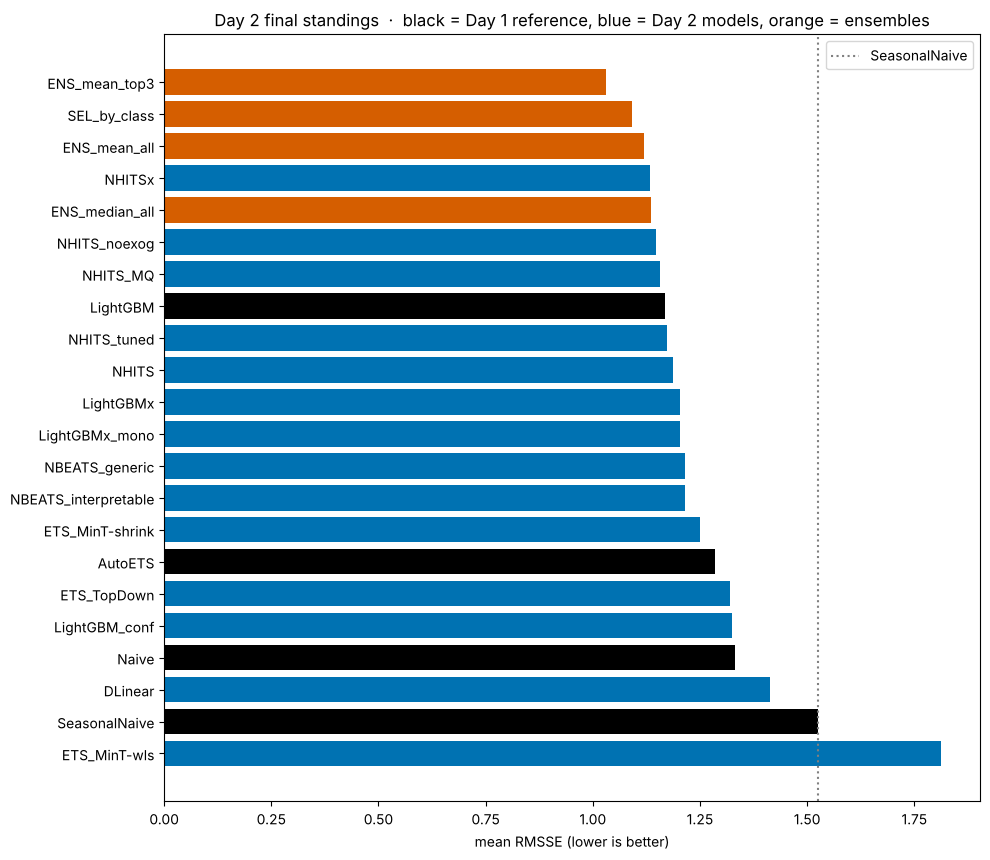

In [12]:
fig, ax = plt.subplots(figsize=(10, 0.35 * len(board) + 1))
colors = [palette[2] if str(l).startswith("07") else palette[1] if str(l).startswith(("0", "day2")) and not str(l).startswith("00")
          else palette[0] for l in board["lab"]]
ax.barh(board["model"][::-1], board["mean_rmsse"][::-1], color=colors[::-1])
snaive = board.loc[board.model == "SeasonalNaive", "mean_rmsse"]
if len(snaive):
    ax.axvline(snaive.iloc[0], color="grey", ls=":", label="SeasonalNaive")
    ax.legend()
ax.set_xlabel("mean RMSSE (lower is better)")
ax.set_title("Day 2 final standings  ·  black = Day 1 reference, blue = Day 2 models, orange = ensembles")
plt.tight_layout()
plt.savefig(bc.RESULTS_DIR / "final_standings.png", dpi=150)

### This morning's questions, answered

| Question from the recap | What today's numbers say (reference run) |
|---|---|
| Is the GBDT strong because it is **global** or because of **covariates**? | Mostly **global**: NHITS without covariates (≈ 1.15) already matches LightGBM (≈ 1.17); covariates add a few percent, mostly in promo weeks |
| Can a neural net learn the hand-built features? | **Yes, about as well**, from the raw window |
| What does it cost? | 20–30 s per neural fit vs 1.6 s; tuning ≈ 474 s for 1 % |
| Does it **respond to price** the right way? | **Direction yes, size no**: promo lift +9 % to +28 % vs +72 % in the data |
| Best of the day? | The **average of the top 3** (≈ 1.03), about 12 % better than the best Day 1 model |

## A decision framework to take home

1. **Baselines first.** If you cannot beat SeasonalNaive / ETS on most series, stop and look at the data.
2. **Global before deep.** A GBDT with lags and covariates is the bar. A neural model has to beat it by more
   than the fold-to-fold noise to justify its training and serving cost.
3. **Tune the few things that matter** (lookback, learning rate / steps, scaler, loss) and stop.
4. **Check responsiveness** before accuracy if the forecast drives pricing or promotion decisions.
5. **Foundation models** are a strong zero-shot baseline; fine-tune only when you have the data and the
   inference budget, and it beats your tuned global model on validation.
6. **Reconcile** when several levels are consumed; pick the method by the level that matters.
7. **Report win rates and segment results**, not only a mean, and **ensemble** when no single model dominates.